# Example 8.5: Estimation of spectra from time series data


This example provides an overview of spectral estimation from time series data. It's worth noting that in this example, we're "cheating" slightly, as we already know the exact spectrum of the process for comparison. In real-world structural dynamics applications, however, we must bridge the gap between the time domain and the frequency domain without prior knowledge of the underlying spectrum.

Consider a time series $x(t)$, representing the response of a structure. This time series could originate from computer simulations or be measured data, typically collected using accelerometers. For our purposes, we assume that the data is generated by a stationary stochastic process, meaning that $x(t)$ is one realization of a process with a spectral density function $S_x(\omega)$.

We assume a zero-mean process that is ergodic in its second-order statistics, so that time averages can represent ensemble correlations and the integrated PSD equals the variance.

Our goal is to estimate the spectrum $S_x(\omega)$ from this time series data. We use the term *estimate* because, in practical settings, the exact spectrum is unknowable unless we have an infinitely long time series that contains no measurement noise. We have to accept some uncertainties when we deal with measurement data.

There exist several methods that estimate spectra from time domain data, most of which utilize the Fourier transform. Below, we demonstrate two simple and important methods.





## Method 1: FFT

The first method is based on the discrete Fourier transform of the sampled time series. For $N$ samples $x_j=x(jt_s)$, we use the course normalization

$$ X_k=\frac{1}{N}\sum_{j=0}^{N-1}x_j e^{-i2\pi jk/N}, \qquad T=Nt_s. $$

In Python, these coefficients are obtained as `np.fft.fft(x)/N`. The two-sided spectrum estimate in Hz is

$$ \widehat S_x(f_k)=T X_k\bar X_k=T|X_k|^2. $$

Here, the bar denotes complex conjugation and the hat distinguishes an estimate from the true PSD. To explain the scaling, consider the following finite-record derivation.

The true spectrum is the Fourier transform of the autocorrelation function:

$$ S_x(\omega)=\frac{1}{2\pi}\int_{-\infty}^{\infty}R_{xx}(\tau)e^{-i\omega\tau}\,\mathrm d\tau,
\qquad R_{xx}(\tau)=E[x(t)x(t+\tau)]. $$

For a record of duration $T$, define $x_T(t)=x(t)$ for $0\leq t<T$ and $x_T(t)=0$ outside this interval. A finite-record estimate of the autocorrelation is

$$ \widehat R_{xx,T}(\tau)=\frac{1}{T}\int_{-\infty}^{\infty}x_T(t)x_T(t+\tau)\,\mathrm dt. $$

The normalization is $1/T$ at all lags; the zero extension means that only overlapping parts of the record contribute. Fourier transforming this estimate gives

$$ \widehat S_{x,T}(\omega)=\frac{1}{2\pi T}\int_{-\infty}^{\infty}\int_{-\infty}^{\infty}
x_T(t)x_T(t+\tau)e^{-i\omega\tau}\,\mathrm dt\,\mathrm d\tau. $$

Now change variables to $\alpha=t$ and $\beta=t+\tau$. Since the zero-extended signal is defined over the whole real line, the double integral can be split into two single integrals:

$$
\widehat S_{x,T}(\omega)
=\frac{1}{2\pi T}
\left(\int_{-\infty}^{\infty}x_T(\alpha)e^{i\omega\alpha}\,\mathrm d\alpha\right)
\left(\int_{-\infty}^{\infty}x_T(\beta)e^{-i\omega\beta}\,\mathrm d\beta\right)
=\frac{2\pi}{T}|X_T(\omega)|^2,
$$

where the continuous Fourier transform follows the course convention:

$$ X_T(\omega)=\frac{1}{2\pi}\int_{-\infty}^{\infty}x_T(t)e^{-i\omega t}\,\mathrm dt. $$

For sampled data, approximate this integral by a sum at the DFT frequencies $\omega_k=2\pi f_k$:

$$ X_T(\omega_k)\approx\frac{t_s}{2\pi}\sum_{j=0}^{N-1}x_j e^{-i2\pi jk/N}
=\frac{T}{2\pi}X_k. $$

This gives the normalization of the discrete spectrum estimate

$$ \widehat S_x(\omega_k)=\frac{T}{2\pi}|X_k|^2. $$

Finally, converting the density from rad/s to Hz gives

$$ \widehat S_x(f_k)=2\pi\widehat S_x(\omega_k)=T|X_k|^2. $$

Under the usual regularity conditions, the expected finite-record spectrum estimate approaches the true PSD as the duration increases:

$$ S_x(\omega)=\lim_{T\rightarrow\infty}E[\widehat S_{x,T}(\omega)]. $$

This is a statement about the expected estimate, not pointwise convergence of a single unaveraged spectrum estimate.

Different Fourier-transform conventions lead to different normalization factors. Correct scaling is needed to preserve the variance relation for the zero-mean process:

$$ \sigma_x^2=\int_{-\infty}^{\infty}S_x(\omega)\,\mathrm d\omega
=\int_{-\infty}^{\infty}S_x(f)\,\mathrm df. $$

The derivation above uses two-sided PSDs; the code below converts the estimate to a one-sided PSD for comparison with the prescribed spectrum.

We will now define a spectrum and use it to simulate a time series. Then, the spectrum of the process will be re-estimated. We use the IRFFT simulation method from Example 3.6 and retain only a shorter part of each realization; using the complete simulation period would reproduce the prescribed fixed-amplitude spectrum at the FFT bins and hide the variability of the estimate.


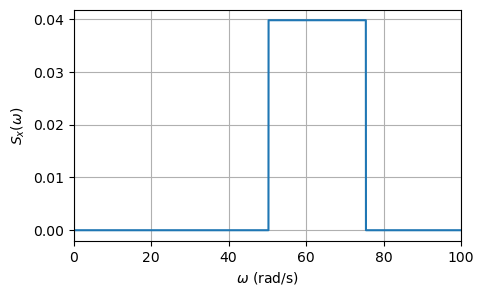

In [2]:
# Simulate time series from a known spectrum using Example 3.6

import numpy as np
from matplotlib import pyplot as plt
from scipy import signal as spsi

# Choose a long simulation period and sampling interval, then construct the FFT grid.
ts = 0.01  # Sampling interval [s]
T_full_requested = 600.0  # Requested full simulation period [s]
N_full = int(round(T_full_requested / ts))
if N_full % 2 == 0:
    N_full += 1  # Use odd N, as in Example 3.6
T_full = N_full * ts
t_sim = np.arange(N_full) * ts
domega = 2 * np.pi / T_full
n_freq = (N_full + 1) // 2
omega_axis = np.arange(n_freq) * domega

omega1 = 2*np.pi*8  # Lower cutoff frequency [rad/s]
omega2 = 2*np.pi*12  # Upper cutoff frequency [rad/s]
sigma_x = 1.0  # Standard deviation of the process

Sx = np.zeros_like(omega_axis)
in_band = (omega_axis >= omega1) & (omega_axis <= omega2)
Sx[in_band] = sigma_x**2 / (omega2 - omega1)  # One-sided PSD

plt.figure(figsize=(5,3))
plt.plot(omega_axis,Sx)
plt.ylabel(r'$S_x(\omega)$')
plt.xlabel(r'$\omega$ (rad/s)')
plt.xlim(0,100)
plt.grid()


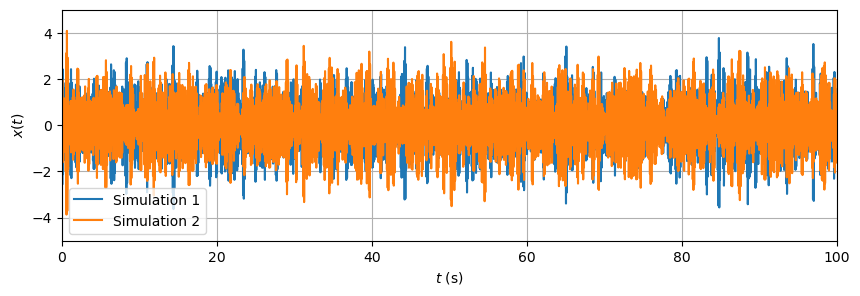

In [3]:
N_sim = 100  # Number of simulations
T_sim = 100  # Retained measurement duration [s]

N_record = int(round(T_sim / ts))
t = t_sim[:N_record]
x_all = [None] * N_sim

# Cosine amplitudes and course-normalized coefficients, as in Example 3.6.
Ak = np.sqrt(2 * Sx * domega)
Ak[0] = 0.0
for k in range(N_sim):
    phi = np.random.uniform(0, 2*np.pi, n_freq)
    Xk = (Ak / 2) * np.exp(1j * phi)
    Xk[0] = 0.0
    x_full = N_full * np.fft.irfft(Xk, n=N_full)
    x_all[k] = x_full[:N_record].copy()

# Plot part of the simulated time series
plt.figure(figsize=(10,3))
plt.plot(t,x_all[0],label = 'Simulation 1')
plt.plot(t,x_all[1],label = 'Simulation 2')
plt.ylabel(r'$x(t)$')
plt.xlabel(r'$t$ (s)')
plt.xlim(0,100)
plt.ylim(-5,5)
plt.grid()
plt.legend()

### Spectrum from FFT with one time series

We will now use the FFT method to find the spectrum from the time series. This is called the estimated spectrum or the empirical spectrum. We will start with estimating the spectrum from just *one* time series.

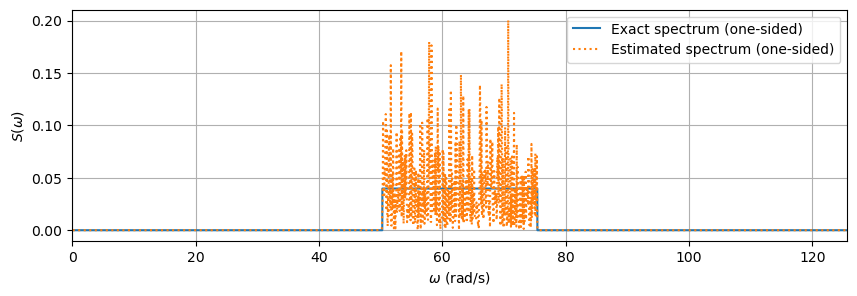

In [4]:
# Estimate spectrum from one time series

ts=t[1]-t[0] # Sampling interval
N = len(t)
T = N*ts # Record duration used in the DFT normalization

Xfft = np.fft.fftshift(np.fft.fft(x_all[0]))/N
f_fft = np.fft.fftshift(np.fft.fftfreq(N, d=ts)) # Frequency axis in Hz

Sx_est_twosided=T*np.real(Xfft*np.conj(Xfft)) # Estimate spectrum (two-sided and function of Hz)

omega_fft=f_fft[f_fft>0]*2*np.pi # One-sided frequency axis in rad/s
Sx_est=Sx_est_twosided[f_fft>0]/(2*np.pi)*2 # One-sided spectrum as function of rad/s

# Plot and compare with exact solution
plt.figure(figsize=(10,3))   
plt.plot(omega_axis,Sx,'-' ,label = 'Exact spectrum (one-sided)') 
plt.plot(omega_fft,Sx_est,':' ,label = 'Estimated spectrum (one-sided)') 
plt.xlabel(r'$\omega$ (rad/s)')
plt.ylabel(r'$S(\omega)$')
plt.xlim(0,20*2*np.pi)
plt.grid()
plt.legend()

We see that the two spectra generally match, but the estimated spectrum is very "noisy". A longer record improves frequency resolution, but does not generally reduce the pointwise variability of an unaveraged spectrum estimate.

Averaging estimates from multiple independent realizations reduces this variability. Alternatively, Welch's method averages estimates from segments of one sufficiently long record.


### FFT-based spectrum with multiple time series


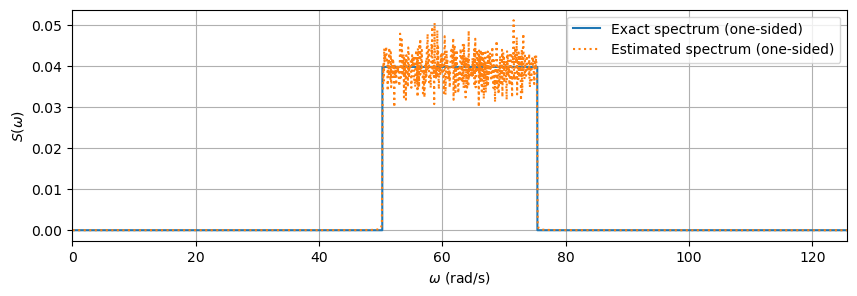

In [5]:
# Estimate spectrum from multiple time series

Sx_est_all=np.zeros((N_sim,Sx_est.shape[0]))

for k in range(N_sim): # Loop over all time series

    Xfft = np.fft.fftshift(np.fft.fft(x_all[k]))/N
    f_fft = np.fft.fftshift(np.fft.fftfreq(N, d=ts)) # Frequency axis in Hz

    Sx_est_twosided=T*np.real(Xfft*np.conj(Xfft)) # Estimate spectrum (two-sided and function of Hz)
        
    omega_fft=f_fft[f_fft>0]*2*np.pi # One-sided frequency axis in rad/s
    Sx_est=Sx_est_twosided[f_fft>0]/(2*np.pi)*2 # One-sided spectrum as function of rad/s
    
    Sx_est_all[k,:]=Sx_est
    
Sx_est_averaged=np.mean(Sx_est_all,axis=0)

# Plot and compare with exact solution
plt.figure(figsize=(10,3))   
plt.plot(omega_axis,Sx,'-' ,label = 'Exact spectrum (one-sided)') 
plt.plot(omega_fft,Sx_est_averaged,':' ,label = 'Estimated spectrum (one-sided)') 
plt.xlabel(r'$\omega$ (rad/s)')
plt.ylabel(r'$S(\omega)$')
plt.xlim(0,20*2*np.pi)
plt.grid()
plt.legend()

The result is now an estimated spectrum that almost fits the rectangular spectrum. You can try to increase/decrease the variable *N_sim* from 2 to 100 to observe how it converges. You can also try to vary *T_sim* from 10 to 300 s to see its effect on the frequency resolution.

What if we dont have multiple realizations and still want to improve the quality? The next method will produce a much more smooth spectrum from just one time series.

## Method 2: Welch's method

When dealing with measurement data, we do not have multiple time series we can average. As a compromise, we take a single time series and divide it into several segments, as shown in the figure below. This is the idea of Welch's method.

The number of divisions (or equivalently, the length of each segment) is defined by the user. These segments can overlap, with a typical choice being 50% overlap, which is the default setting in most programming environments.

The spectrum is calculated by the FFT method for each segment, and finally the averaged spectrum is the Welch estimate. Since this is an averaging method, the noisy behavior in the previous method will to a large extent be mitigated.

<img src="./figures/Welch.png" width="600px">

The choice of the number of divisions involves a trade-off with advantages and disadvantages:

- **More divisions (=shorter segments)** leads to greater averaging and, therefore, a smoother spectrum. However, the frequency resolution $\Delta f$ or $\Delta \omega$ in the frequency axis becomes bigger. 
- **Less divisions (=longer segments)** leads to less averaging and thus a more noisy spectrum. The advantage is that the frequency resolution is finer.

We may observe these effects if the code example below is changed. Here, `Ndivisions` determines the segment length relative to the full record; with 50% overlap, `Ndivisions=10` gives 19 overlapping segments for the current settings.

Other useful settings to consider:

- **Windowing**: the time series of each segment is weighted by a Hann window to reduce spectral leakage from the finite segment boundaries.
- **NFFT**: this parameter zero pads the time series to a given length. For instance, if the time series is 200 points long, setting NFFT=256=2^8 will add 56 zeros at the end. Zero-padding gives a finer frequency grid, but does not improve the ability to resolve nearby components; that depends on segment duration and window choice. A power-of-two FFT length can also be computationally efficient.
- **Return one-sided**: this is usually convenient, can it be turned off if a two-sided spectrum is desired.
- **Detrend**: a detrending of the time series is recommended; this means subtracting the mean value so that the signal becomes zero mean. If turned off, the spectrum will have a peak at 0 Hz, which corresponds to a static component of the process. The static component is usually not of interest when looking at a spectrum.


(10000,)
1000


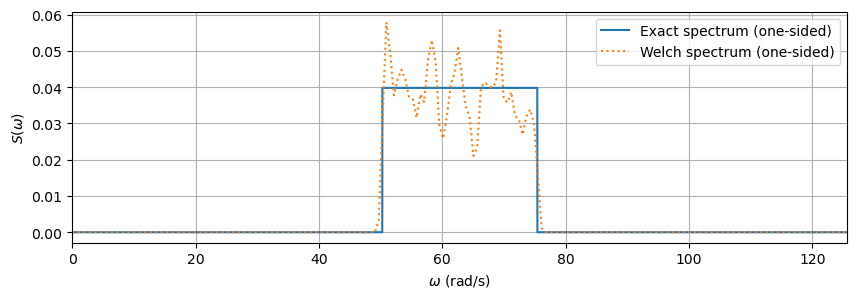

In [6]:
import scipy

Ndivisions=10 # Controls segment length; not the number of overlapping segments
Nwindow=int(np.ceil(len(t)/Ndivisions)) # Length of window/segment

print(np.shape(x_all[0]))
print(Nwindow)

Nfft_pow2 = 2**int(np.ceil(np.log2(Nwindow))) # Next power of 2 for zero padding

# Call welch from scipy signal processing
f_welch, Sx_welch_temp=scipy.signal.welch(x_all[0], fs=1/ts, window='hann', nperseg=Nwindow, noverlap=None, nfft=Nfft_pow2, detrend='constant', return_onesided=True, scaling='density', axis=- 1, average='mean')

omega_welch=f_welch*2*np.pi # Transform to rad/s
Sx_welch=Sx_welch_temp/(2*np.pi) # Transform to rad/s

# Plot and compare with exact solution
plt.figure(figsize=(10,3))   
plt.plot(omega_axis,Sx,'-' ,label = 'Exact spectrum (one-sided)') 
plt.plot(omega_welch,Sx_welch,':' ,label = 'Welch spectrum (one-sided)')
plt.xlabel(r'$\omega$ (rad/s)')
plt.ylabel(r'$S(\omega)$')
plt.xlim(0,20*2*np.pi)
plt.grid()
plt.legend()

From the figure above, you see that the Welch spectrum matches quite well. The estimated spectrum is much smoother, but this comes at the cost of a reduced spectral precision (frequency resolution) compared to the FFT method.

## Cross-spectral densities

Until now, we have only considered estimation of auto spectra. Cross-spectrum can be estimated from the FFT in a similar manner:

$$ S_{xy}(f_k) = T \cdot X_{k} \bar{Y}_k $$


When we deal with cross-spectra, or a cross-spectral density matrix, we usually arrange the data as a 3d array shown in the figure below. The two first dimensions represent the DOF dimensions, while the last is the frequency dimension. To obtain the cross-spectral density matrix at one specific frequency, we have to select a "slice" of the 3d array.


<img src="./figures/Spectrum_3d_array.svg" align = "center" style="width:600px" >


The code below shows how to construct the cross spectral density matrix. We call the *csd* function in a double for loop, this is the same as *welch* except that it takes in two signals $x(t)$ and $y(t)$. If $x=y$, then an auto spectrum is obtained.

We construct two partially correlated processes from independent realizations $x_1(t)$ and $x_2(t)$ with the same zero-mean spectrum $S_x(\omega)$:

$$y_1(t)=x_1(t),\qquad y_2(t)=a\left[\rho x_1(t)+\sqrt{1-\rho^2}\,x_2(t)\right].$$

Their theoretical spectral density matrix is

$$\mathbf S_y(\omega)=S_x(\omega)\begin{bmatrix}1&a\rho\\a\rho&a^2\end{bmatrix}.$$

With $\rho=0.7$ and $a=0.5$, the correlation coefficient is $0.7$, the magnitude-squared coherence is $\rho^2=0.49$ within the excited band, and the cross-spectrum is $0.35S_x(\omega)$. All theoretical imaginary parts are zero. Estimates from finite records fluctuate around these values. The dashed curves below show the theoretical real spectra.


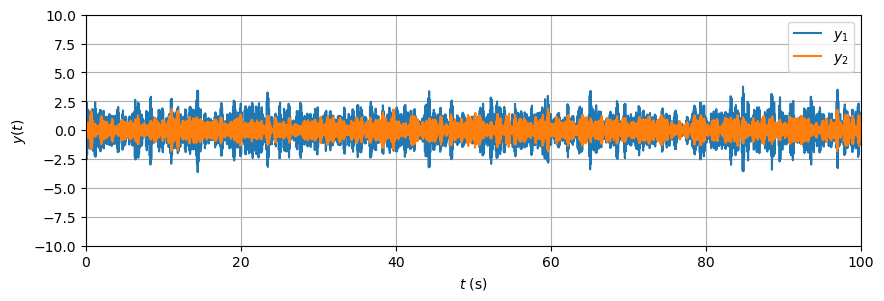

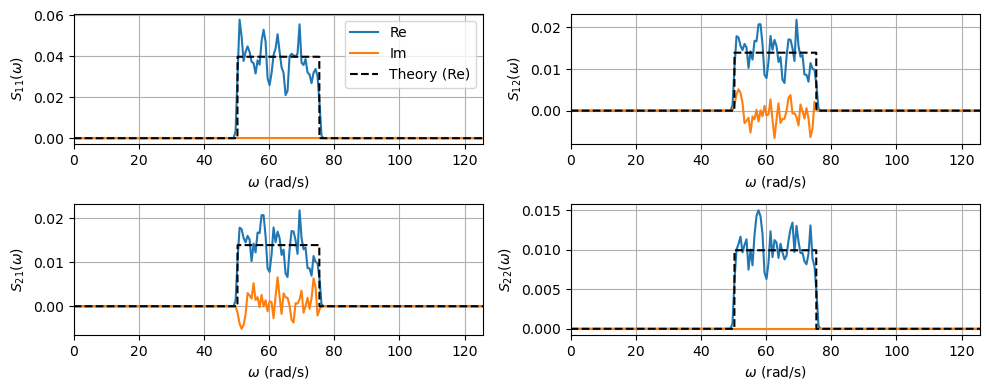

In [7]:
# Welch estimate of cross-spectral density

# Mix two independent realizations with the same spectrum.
rho = 0.7  # Target correlation coefficient
a = 0.5    # Standard deviation of y_2 relative to y_1

y = np.zeros((2, len(t)))
y[0, :] = x_all[0]
y[1, :] = a * (rho * x_all[0] + np.sqrt(1 - rho**2) * x_all[1])

# Plot part of the simulated time series
plt.figure(figsize=(10,3))
plt.plot(t,y[0,:],label = r'$y_1$')
plt.plot(t,y[1,:],label = r'$y_2$')
plt.ylabel(r'$y(t)$')
plt.xlabel(r'$t$ (s)')
plt.xlim(0,100)
plt.ylim(-10,10)
plt.grid()
plt.legend()

Ndivisions=10 # Controls segment length; not the number of overlapping segments
Nwindow=int(np.ceil(len(t)/Ndivisions)) # Length of window
Nfft_pow2 = 2**int(np.ceil(np.log2(Nwindow))) # Next power of 2

# Spectral matrix
S_welch=np.zeros((2,2,np.int32(Nfft_pow2/2+1)),dtype=np.complex128)

# Fill spectral matrix by taking the cross spectral density between each of the 2 time series
for k1 in range(2):
    for k2 in range(2):
            f, S_Hz=scipy.signal.csd(y[k1,:],y[k2,:], fs=1/ts, window='hann', nperseg=Nwindow, noverlap=None, nfft=Nfft_pow2, detrend='constant', return_onesided=True, scaling='density', axis=-1, average='mean')
            
            omega_welch=f*2*np.pi # Frequency axis in rad/s
            S_welch[k1,k2,:]=S_Hz/(2*np.pi) # Spectrum in rad/s
            
# Theoretical spectral matrix for comparison
S_theory = np.array([[1.0, a*rho], [a*rho, a**2]])[:, :, None] * Sx

# Plot spectrum
fig, axs = plt.subplots(2,2,figsize=(10,4))    
for k1 in range(2):
    for k2 in range(2):
        ax = axs[k1,k2]
        ax.plot(omega_welch,np.real(S_welch[k1,k2,:]),label='Re')
        ax.plot(omega_welch,np.imag(S_welch[k1,k2,:]),label='Im')
        ax.plot(omega_axis, S_theory[k1,k2,:], 'k--', label='Theory (Re)')
        ax.set_ylabel(('$S_{' + str(k1+1) + str(k2+1) + r'}(\omega)$'))
        ax.set_xlabel(r'$\omega$ (rad/s)')
        ax.grid(True)
        #ax.set_yscale('log')
        ax.set_xlim(0,20*2*np.pi)
        
plt.tight_layout()
axs[0,0].legend()

It can be verified that the auto spectra on the diagonal are purely real, but the cross-spectra have both a real and an imaginary component.